# Bassac River Forecasting — Step 1 & 2: EDA & Data Cleaning

In [1]:
# Setup & load all 4 raw datasets
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAW_DIR = Path('..').resolve() / 'data' / 'raw'
PROCESSED_DIR = Path('..').resolve() / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

bassac_raw = pd.read_csv(RAW_DIR / 'Bassac_01_ori.csv')
dhrw_raw = pd.read_csv(RAW_DIR / 'dhrw_water_level_2020_2026.csv')
glofas_raw = pd.read_csv(RAW_DIR / 'glofas_discharge_phnompenh.csv')
nasa_raw = pd.read_csv(RAW_DIR / 'POWER_Point_Daily_20200602_20261122_011d05N_105d07E_UTC.csv', skiprows=9)
print('Loaded all 4 raw CSV files.')


Loaded all 4 raw CSV files.


In [2]:
# Check Bassac_01 (Koh Thum)
print(bassac_raw.head())
bassac_raw.info()
print(bassac_raw.describe())


               Date    WL
0  19/06/2020 12:00  1.18
1  19/06/2020 12:15  1.16
2  19/06/2020 12:30  1.14
3  19/06/2020 12:45  1.12
4  19/06/2020 13:00  1.10
<class 'pandas.DataFrame'>
RangeIndex: 127606 entries, 0 to 127605
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Date    127606 non-null  str    
 1   WL      127606 non-null  float64
dtypes: float64(1), str(1)
memory usage: 3.9 MB
                  WL
count  127606.000000
mean        2.530803
std         1.313128
min         0.410000
25%         1.450000
50%         2.040000
75%         3.500000
max         5.620000


In [3]:
# Check DHRW (Koh Khel + other stations)
print(dhrw_raw.head())
dhrw_raw.info()
print(dhrw_raw.describe())


         date  Stung_Treng  Kratie  Kampong_Cham  Chaktomuk  Neak_Loeung  \
0  2020-06-17         3.13    8.09          3.14       1.68         1.32   
1  2020-06-18         3.16    8.24          3.34       1.77         1.34   
2  2020-06-19         3.11    8.28          3.44       1.81         1.22   
3  2020-06-20         3.17    8.20          3.44       1.86         1.20   
4  2020-06-21         3.20    8.27          3.46       1.90         1.14   

   Koh_Khel  Prek_Kdam  
0      1.65       0.76  
1      1.60       0.96  
2      1.77       0.93  
3      1.83       0.89  
4      1.88       0.97  
<class 'pandas.DataFrame'>
RangeIndex: 1511 entries, 0 to 1510
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          1511 non-null   str    
 1   Stung_Treng   1511 non-null   float64
 2   Kratie        1511 non-null   float64
 3   Kampong_Cham  1511 non-null   float64
 4   Chaktomuk     1511 non-null   float

In [4]:
# Check GloFAS (Phnom Penh discharge)
print(glofas_raw.head())
glofas_raw.info()
print(glofas_raw.describe())


         date        Q
0  2018-01-01  4119.98
1  2018-01-02  4158.11
2  2018-01-03  4177.30
3  2018-01-04  4167.69
4  2018-01-05  4119.98
<class 'pandas.DataFrame'>
RangeIndex: 3235 entries, 0 to 3234
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    3235 non-null   str    
 1   Q       3235 non-null   float64
dtypes: float64(1), str(1)
memory usage: 82.3 KB
                   Q
count    3235.000000
mean    13951.141385
std     15573.134264
min         8.980000
25%      1677.800000
50%      6682.440000
75%     23932.170000
max    100229.510000


In [5]:
# Check NASA POWER (Daily rainfall)
print(nasa_raw.head())
nasa_raw.info()
print(nasa_raw.describe())


   YEAR  MO  DY  PRECTOTCORR
0  2020   6   2        19.36
1  2020   6   3         7.36
2  2020   6   4         9.64
3  2020   6   5        19.16
4  2020   6   6        14.58
<class 'pandas.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   YEAR         2363 non-null   int64  
 1   MO           2363 non-null   int64  
 2   DY           2363 non-null   int64  
 3   PRECTOTCORR  2363 non-null   float64
dtypes: float64(1), int64(3)
memory usage: 74.0 KB
              YEAR           MO          DY  PRECTOTCORR
count  2363.000000  2363.000000  2363.00000  2363.000000
mean   2023.141346     6.658062    15.69361     5.479843
std       1.889943     3.384336     8.79155    13.610622
min    2020.000000     1.000000     1.00000     0.000000
25%    2022.000000     4.000000     8.00000     0.070000
50%    2023.000000     7.000000    16.00000     1.810000
75%    2025.000000    10.0000

In [6]:
# Clean Bassac_01 (15-min sensor -> 24h daily average)
bassac_raw['dt'] = pd.to_datetime(bassac_raw['Date'], format='%d/%m/%Y %H:%M', errors='coerce')
bassac_raw['WL'] = pd.to_numeric(bassac_raw['WL'], errors='coerce')

clean_15min = (
    bassac_raw
    .dropna(subset=['dt', 'WL'])
    .sort_values('dt')
    .drop_duplicates(subset=['dt'])
)

# Average 96 readings/day into 1 daily value to remove ocean tide swings
sensor_by_time = clean_15min.set_index('dt')['WL']
daily_avg_wl = sensor_by_time.resample('D').mean()
readings_per_day = sensor_by_time.resample('D').count()

bassac_daily = pd.DataFrame({
    'date': daily_avg_wl.index.strftime('%Y-%m-%d'),
    'WL': daily_avg_wl.values,
    'n_readings': readings_per_day.values,
})
bassac_daily.loc[bassac_daily['n_readings'] < 90, 'WL'] = np.nan

# Fill Dec 2021 - Mar 2022 outage using previous dry season shape
daily_series = bassac_daily.assign(dt=pd.to_datetime(bassac_daily['date'])).set_index('dt')['WL']
outage_dates = daily_series.loc['2021-12-01':'2022-03-18'].index
last_year_shape = daily_series.loc[outage_dates - pd.DateOffset(years=1)].values
start_diff = daily_series.loc['2021-11-30'] - daily_series.loc[pd.Timestamp('2021-11-30') - pd.DateOffset(years=1)]
end_diff = daily_series.loc['2022-03-19'] - daily_series.loc[pd.Timestamp('2022-03-19') - pd.DateOffset(years=1)]
daily_series.loc[outage_dates] = np.round(last_year_shape + np.linspace(start_diff, end_diff, len(outage_dates)), 4)
bassac_daily['WL'] = daily_series.values

bassac_daily.to_csv(PROCESSED_DIR / 'bassac_daily.csv', index=False)
print('bassac_daily:', bassac_daily.shape, '| Valid WL:', bassac_daily['WL'].notna().sum(), '| Missing:', bassac_daily['WL'].isna().sum())


bassac_daily: (1438, 3) | Valid WL: 1435 | Missing: 3


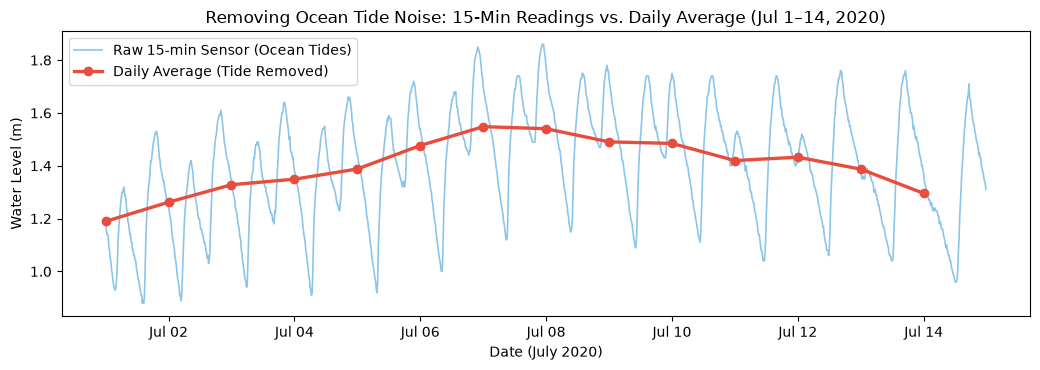

In [7]:
# Figure 1: 14-day zoom showing raw 15-min tidal waves vs. cleaned daily average
sample_14days_15m = clean_15min[(clean_15min['dt'] >= '2020-07-01') & (clean_15min['dt'] < '2020-07-15')]
sample_14days_avg = bassac_daily[(bassac_daily['date'] >= '2020-07-01') & (bassac_daily['date'] <= '2020-07-14')].copy()
sample_14days_avg['dt'] = pd.to_datetime(sample_14days_avg['date'])

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.plot(sample_14days_15m['dt'], sample_14days_15m['WL'], label='Raw 15-min Sensor (Ocean Tides)', color='#5dade2', alpha=0.7, linewidth=1.2)
ax.plot(sample_14days_avg['dt'], sample_14days_avg['WL'], 'o-', label='Daily Average (Tide Removed)', color='#e74c3c', linewidth=2.4, markersize=6)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_ylabel('Water Level (m)')
ax.set_xlabel('Date (July 2020)')
ax.set_title('Removing Ocean Tide Noise: 15-Min Readings vs. Daily Average (Jul 1–14, 2020)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


In [8]:
# Clean Koh Khel water level (keep Bassac station only & fill 1-day gaps)
kohkhel_base = pd.DataFrame({
    'date': pd.to_datetime(dhrw_raw['date'], errors='coerce'),
    'WL_raw': pd.to_numeric(dhrw_raw['Koh_Khel'], errors='coerce'),
}).dropna().sort_values('date').drop_duplicates(subset=['date']).reset_index(drop=True)

before_jul2024 = kohkhel_base[kohkhel_base['date'] < '2024-07-01'].copy()
from_jul2024 = kohkhel_base[kohkhel_base['date'] >= '2024-07-01'].set_index('date')['WL_raw'].asfreq('D')
from_jul2024 = from_jul2024.interpolate(method='linear', limit=1).round(2).reset_index()

kohkhel_daily = pd.concat([before_jul2024, from_jul2024], ignore_index=True).sort_values('date').reset_index(drop=True)
kohkhel_daily['date'] = kohkhel_daily['date'].dt.strftime('%Y-%m-%d')
kohkhel_daily.to_csv(PROCESSED_DIR / 'kohkhel_daily.csv', index=False)
print('kohkhel_daily:', kohkhel_daily.shape)


kohkhel_daily: (1511, 2)


In [9]:
# Clean upstream Mekong discharge at Phnom Penh (2020 - 2026)
glofas_daily = pd.DataFrame({
    'date': pd.to_datetime(glofas_raw['date'], errors='coerce'),
    'upstream_discharge': pd.to_numeric(glofas_raw['Q'], errors='coerce'),
}).dropna().sort_values('date').drop_duplicates(subset=['date']).reset_index(drop=True)

glofas_daily = glofas_daily[glofas_daily['date'] >= '2020-06-01'].reset_index(drop=True)
glofas_daily['date'] = glofas_daily['date'].dt.strftime('%Y-%m-%d')
glofas_daily.to_csv(PROCESSED_DIR / 'glofas_daily.csv', index=False)
print('glofas_daily:', glofas_daily.shape)


glofas_daily: (2353, 2)


In [10]:
# Clean daily rainfall at Koh Thum (combine YEAR, MO, DY into date)
nasa_raw['date'] = pd.to_datetime(dict(year=nasa_raw['YEAR'], month=nasa_raw['MO'], day=nasa_raw['DY']), errors='coerce')
nasa_raw['rain_mm'] = pd.to_numeric(nasa_raw['PRECTOTCORR'], errors='coerce')

nasa_rain_daily = nasa_raw[['date', 'rain_mm']].dropna().sort_values('date').drop_duplicates(subset=['date']).reset_index(drop=True)
nasa_rain_daily['date'] = nasa_rain_daily['date'].dt.strftime('%Y-%m-%d')
nasa_rain_daily.to_csv(PROCESSED_DIR / 'nasa_rain_daily.csv', index=False)
print('nasa_rain_daily:', nasa_rain_daily.shape)


nasa_rain_daily: (2363, 2)


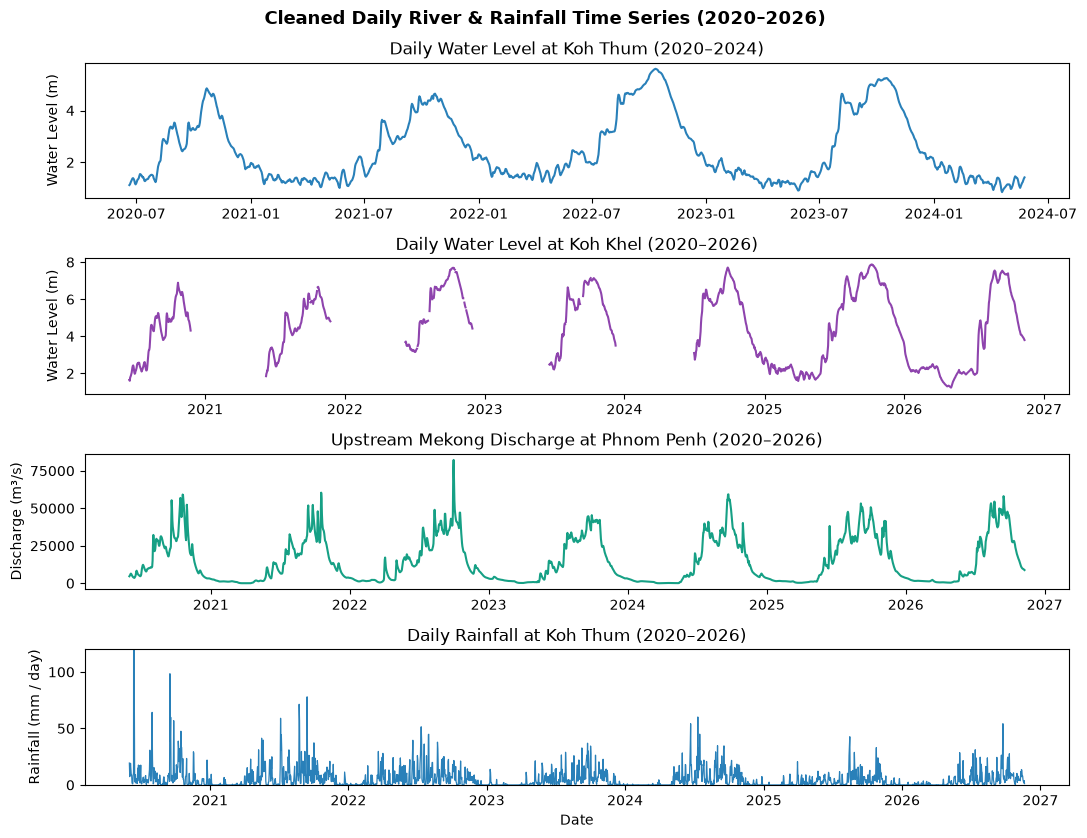

In [11]:
# Figure 2: Plot all 4 cleaned daily series (2020 - 2026)
fig, axes = plt.subplots(4, 1, figsize=(11, 8.5))

axes[0].plot(pd.to_datetime(bassac_daily['date']), bassac_daily['WL'], color='#2980b9')
axes[0].set_title('Daily Water Level at Koh Thum (2020–2024)')
axes[0].set_ylabel('Water Level (m)')

kohkhel_by_day = kohkhel_daily.assign(dt=pd.to_datetime(kohkhel_daily['date'])).set_index('dt')['WL_raw'].asfreq('D')
axes[1].plot(kohkhel_by_day.index, kohkhel_by_day.values, color='#8e44ad')
axes[1].set_title('Daily Water Level at Koh Khel (2020–2026)')
axes[1].set_ylabel('Water Level (m)')

axes[2].plot(pd.to_datetime(glofas_daily['date']), glofas_daily['upstream_discharge'], color='#16a085')
axes[2].set_title('Upstream Mekong Discharge at Phnom Penh (2020–2026)')
axes[2].set_ylabel('Discharge (m³/s)')

axes[3].plot(pd.to_datetime(nasa_rain_daily['date']), nasa_rain_daily['rain_mm'], color='#2980b9', linewidth=0.9)
axes[3].set_ylim(0, 120)
axes[3].set_ylabel('Rainfall (mm / day)')
axes[3].set_xlabel('Date')
axes[3].set_title('Daily Rainfall at Koh Thum (2020–2026)')

fig.suptitle('Cleaned Daily River & Rainfall Time Series (2020–2026)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
